In [26]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [27]:
data=pd.read_csv("../datasets/mnist_train.csv")

In [28]:
data.head()

,label,1x1,1x2,1x3,1x4,1x5,1x6,1x7,1x8,1x9,...,28x19,28x20,28x21,28x22,28x23,28x24,28x25,28x26,28x27,28x28
0,5,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,4,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,9,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [29]:
data=np.array(data)
m,n = data.shape
np.random.shuffle(data)
print(m,n)

60000 785


In [30]:
data_dev=data[0:1000].T
Y_dev=data_dev[0]
X_dev=data_dev[1:n]/255.0

data_train=data[1000:m].T
Y_train=data_train[0]
X_train=data_train[1:n]/255.0

In [31]:
X_train.shape

(784, 59000)

In [32]:
Y_train.shape

(59000,)

In [33]:
def init_params():
    W1 = np.random.randn(10, 784) * np.sqrt(2 / 784)
    b1 = np.zeros((10, 1))

    W2 = np.random.randn(10, 10) * np.sqrt(2 / 10)
    b2 = np.zeros((10, 1))

    return W1, b1, W2, b2

In [34]:
def ReLU(Z):
    return np.maximum(0,Z)

def softmax(Z):
    Z_shifted = Z - np.max(Z, axis=0, keepdims=True)
    exp_Z = np.exp(Z_shifted)
    return exp_Z / np.sum(exp_Z, axis=0, keepdims=True)

def forward_prop(W1,b1,W2,b2,X):
    Z1=W1.dot(X)+b1
    A1=ReLU(Z1)
    Z2=W2.dot(A1)+b2
    A2=softmax(Z2)
    return Z1,A1,Z2,A2

def one_hot(Y):
    one_hot_Y=np.zeros((Y.size,Y.max()+1))
    one_hot_Y[np.arange(Y.size),Y]=1
    one_hot_Y=one_hot_Y.T
    return one_hot_Y

def deriv_ReLU(Z):
    return Z>0

def back_prop(Z1,A1,Z2,A2,W2,X,Y):
    m=Y.size
    one_hot_Y=one_hot(Y)
    dZ2=A2-one_hot_Y
    dW2=1/m*dZ2.dot(A1.T)
    db2=1/m*np.sum(dZ2,axis=1,keepdims=True)
    dZ1=W2.T.dot(dZ2)*deriv_ReLU(Z1)
    dW1=1/m*dZ1.dot(X.T)
    db1=1/m*np.sum(dZ1,axis=1,keepdims=True)
    return  dW1,db1,dW2,db2

def update_params(W1,b1,W2,b2,dW1,db1,dW2,db2,alpha):
    W1=W1-alpha*dW1
    b1=b1-alpha*db1
    W2=W2-alpha*dW2
    b2=b2-alpha*db2
    return W1,b1,W2,b2

In [35]:
def get_predictions(A2):
    return np.argmax(A2,0)

def get_accuracy(predictions,Y):
    print(predictions, Y)
    return np.sum(predictions==Y)/Y.size

def gradient_descent(X, Y, iterations, alpha):

    W1, b1, W2, b2 = init_params()
    for i in range(iterations):

        # Forward propagation
        Z1, A1, Z2, A2 = forward_prop(
            W1, b1, W2, b2, X
        )

        # Backpropagation
        dW1, db1, dW2, db2 = back_prop(
            Z1, A1, Z2, A2, W2, X, Y
        )

        # Update parameters
        W1, b1, W2, b2 = update_params(
            W1, b1, W2, b2,
            dW1, db1, dW2, db2,
            alpha
        )

        if i % 100 == 0:
            _, _, _, A2 = forward_prop(
                W1, b1, W2, b2, X
            )
            predictions = get_predictions(A2)
            print("Iteration:", i)
            print("Accuracy:", get_accuracy(predictions, Y) * 100)

    return W1, b1, W2, b2

In [36]:
W1,b1,W2,b2 = gradient_descent(X_train, Y_train,1000,0.1)

Iteration: 0
[4 4 6 ... 0 5 9] [5 7 3 ... 4 2 2]
Accuracy: 11.810169491525425
Iteration: 100
[5 7 3 ... 4 5 2] [5 7 3 ... 4 2 2]
Accuracy: 83.93050847457627
Iteration: 200
[5 7 3 ... 4 2 2] [5 7 3 ... 4 2 2]
Accuracy: 88.36101694915254
Iteration: 300
[5 7 3 ... 4 2 2] [5 7 3 ... 4 2 2]
Accuracy: 89.57457627118644
Iteration: 400
[5 7 3 ... 4 2 2] [5 7 3 ... 4 2 2]
Accuracy: 90.18474576271186
Iteration: 500
[5 7 3 ... 4 2 2] [5 7 3 ... 4 2 2]
Accuracy: 90.60677966101694
Iteration: 600
[5 7 3 ... 4 2 2] [5 7 3 ... 4 2 2]
Accuracy: 90.91525423728814
Iteration: 700
[5 7 3 ... 4 2 2] [5 7 3 ... 4 2 2]
Accuracy: 91.13220338983051
Iteration: 800
[5 7 3 ... 4 2 2] [5 7 3 ... 4 2 2]
Accuracy: 91.36271186440678
Iteration: 900
[5 7 3 ... 4 2 2] [5 7 3 ... 4 2 2]
Accuracy: 91.53389830508475


In [37]:
test_data = pd.read_csv("../datasets/mnist_test.csv")
test_data = np.array(test_data).T          # each column = one image

Y_test = test_data[0]
X_test = test_data[1:] / 255.0             # same /255 scaling as training
print(X_test.shape, Y_test.shape)          # expect (784, 10000) (10000,)

(784, 10000) (10000,)


In [38]:
def evaluate(X, Y, name):
    _, _, _, A2 = forward_prop(W1, b1, W2, b2, X)
    preds = get_predictions(A2)
    acc = np.mean(preds == Y) * 100
    print(f"{name} accuracy: {acc:.2f}%")
    return preds

train_preds = evaluate(X_train, Y_train, "Train")
dev_preds   = evaluate(X_dev,   Y_dev,   "Dev  ")
test_preds  = evaluate(X_test,  Y_test,  "Test ")

Train accuracy: 91.66%
Dev   accuracy: 90.50%
Test  accuracy: 91.81%


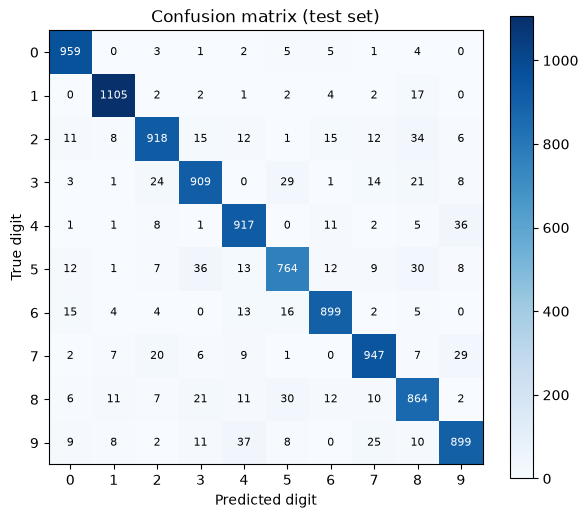

In [39]:
cm = np.zeros((10, 10), dtype=int)
for t, p in zip(Y_test, test_preds):
    cm[t, p] += 1

plt.figure(figsize=(7, 6))
plt.imshow(cm, cmap="Blues")
plt.colorbar()
plt.xlabel("Predicted digit"); plt.ylabel("True digit")
plt.title("Confusion matrix (test set)")
plt.xticks(range(10)); plt.yticks(range(10))
for i in range(10):
    for j in range(10):
        plt.text(j, i, cm[i, j], ha="center", va="center",
                 color="white" if cm[i, j] > cm.max()/2 else "black", fontsize=8)
plt.show()

In [40]:
for d in range(10):
    print(d, f"{cm[d, d] / cm[d].sum() * 100:.1f}%")

0 97.9%
1 97.4%
2 89.0%
3 90.0%
4 93.4%
5 85.7%
6 93.8%
7 92.1%
8 88.7%
9 89.1%


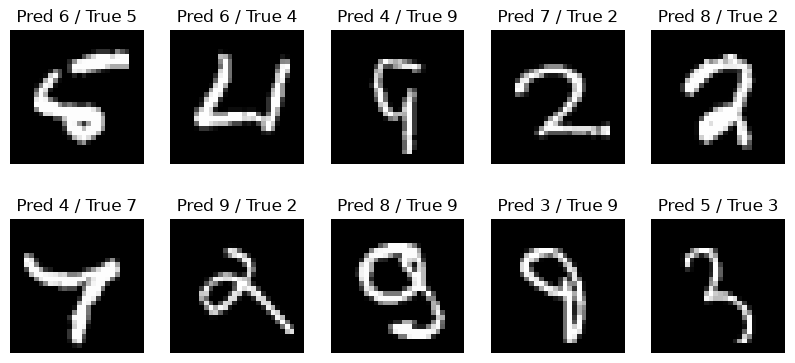

In [41]:
wrong = np.where(test_preds != Y_test)[0][:10]
fig, axes = plt.subplots(2, 5, figsize=(10, 4.5))
for ax, i in zip(axes.flat, wrong):
    ax.imshow(X_test[:, i].reshape(28, 28), cmap="gray")
    ax.set_title(f"Pred {test_preds[i]} / True {Y_test[i]}")
    ax.axis("off")
plt.show()